# EDA for UNSW-NB15

This notebook is for exploratory data analysis only.

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path



In [20]:
train = pd.read_csv("../dataset/raw/UNSW_NB15_training-set.csv")


In [21]:
import os

print(os.getcwd())

/Users/seemasultana/Documents/Federated-IoT/notebooks


In [22]:
import os

print(os.path.exists("../dataset/raw/UNSW_NB15_testing-set.csv"))
print(os.path.exists("../dataset/raw/UNSW_NB15_training-set.csv"))

True
True


In [23]:
train.head()

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


In [24]:
train.columns

Index(['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes',
       'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss',
       'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin',
       'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth',
       'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm',
       'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm',
       'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm',
       'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label'],
      dtype='str')

In [25]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 175341 non-null  int64  
 1   dur                175341 non-null  float64
 2   proto              175341 non-null  str    
 3   service            175341 non-null  str    
 4   state              175341 non-null  str    
 5   spkts              175341 non-null  int64  
 6   dpkts              175341 non-null  int64  
 7   sbytes             175341 non-null  int64  
 8   dbytes             175341 non-null  int64  
 9   rate               175341 non-null  float64
 10  sttl               175341 non-null  int64  
 11  dttl               175341 non-null  int64  
 12  sload              175341 non-null  float64
 13  dload              175341 non-null  float64
 14  sloss              175341 non-null  int64  
 15  dloss              175341 non-null  int64  
 16  sinpkt       

In [26]:
train.isnull().sum()

id                   0
dur                  0
proto                0
service              0
state                0
spkts                0
dpkts                0
sbytes               0
dbytes               0
rate                 0
sttl                 0
dttl                 0
sload                0
dload                0
sloss                0
dloss                0
sinpkt               0
dinpkt               0
sjit                 0
djit                 0
swin                 0
stcpb                0
dtcpb                0
dwin                 0
tcprtt               0
synack               0
ackdat               0
smean                0
dmean                0
trans_depth          0
response_body_len    0
ct_srv_src           0
ct_state_ttl         0
ct_dst_ltm           0
ct_src_dport_ltm     0
ct_dst_sport_ltm     0
ct_dst_src_ltm       0
is_ftp_login         0
ct_ftp_cmd           0
ct_flw_http_mthd     0
ct_src_ltm           0
ct_srv_dst           0
is_sm_ips_ports      0
attack_cat 

In [27]:
train["label"].value_counts()

label
1    119341
0     56000
Name: count, dtype: int64

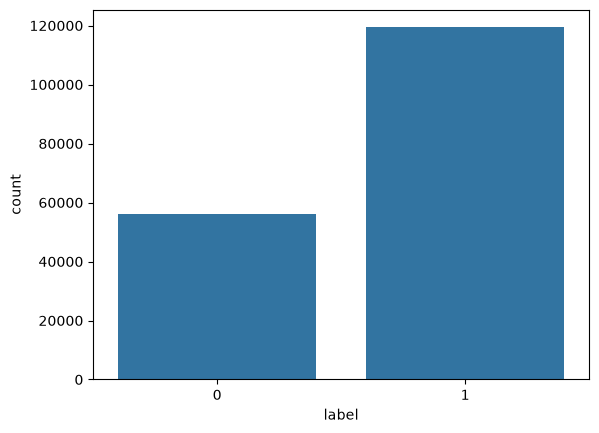

In [30]:
sns.countplot(x="label", data=train)

plt.show()

In [33]:
train["attack_cat"].value_counts()

attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64

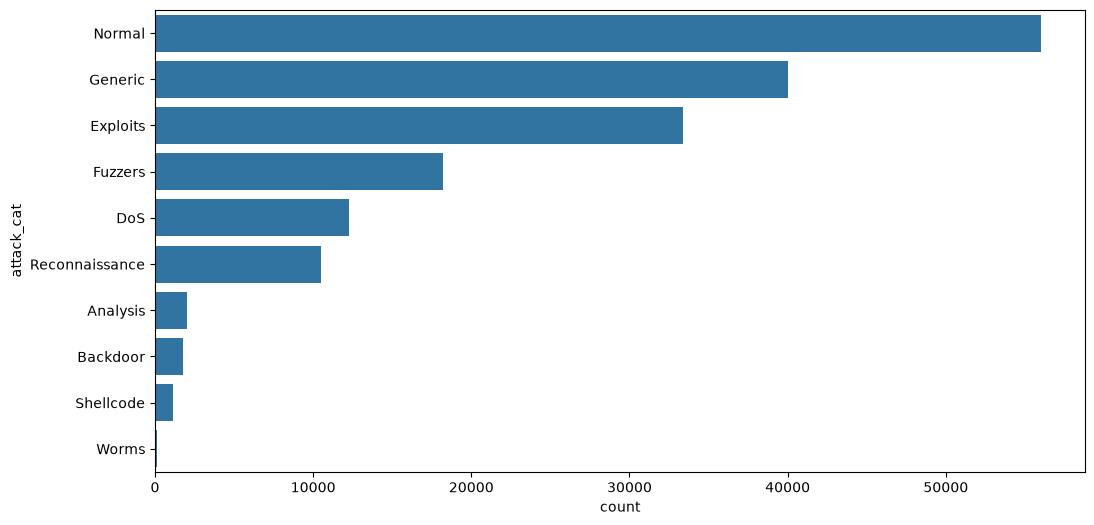

In [36]:
plt.figure(figsize=(12,6))

sns.countplot(
    y="attack_cat",
    data=train,
    order=train["attack_cat"].value_counts().index
)

plt.show()

In [37]:
print(train.shape)



(175341, 45)


In [39]:
train.select_dtypes(include=np.number).columns

Index(['id', 'dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl',
       'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit',
       'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat',
       'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src',
       'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm',
       'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd',
       'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'label'],
      dtype='str')

In [40]:
train.select_dtypes(include="object").columns

/var/folders/wg/tshzh5d50jlgjbs42t3czymm0000gn/T/ipykernel_80821/244920003.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  train.select_dtypes(include="object").columns


Index(['proto', 'service', 'state', 'attack_cat'], dtype='str')

In [42]:
numeric = train.select_dtypes(include=np.number)
corr = numeric.corr()

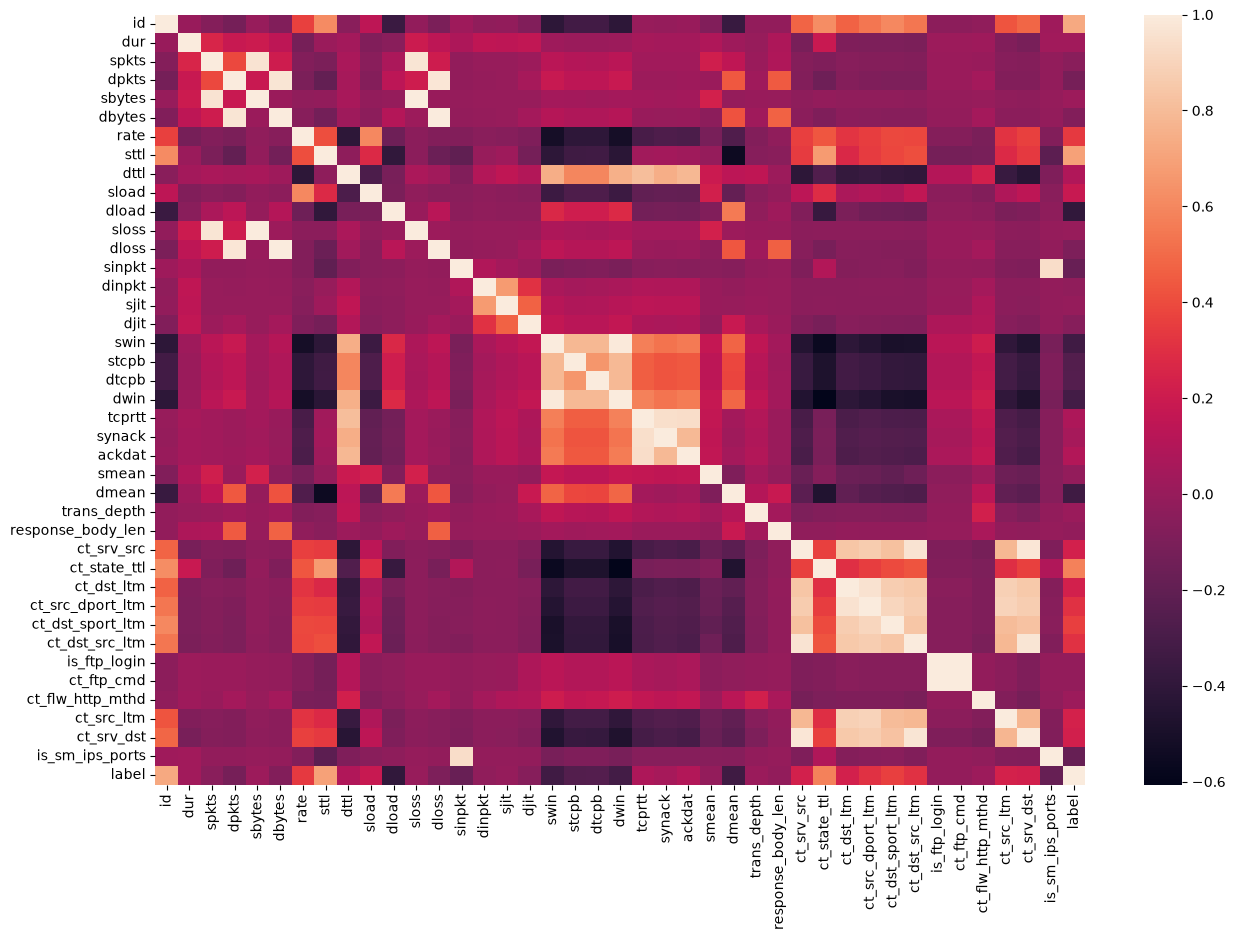

In [43]:
plt.figure(figsize=(15,10))

sns.heatmap(corr)

plt.show()

In [45]:
missing = train.isnull().sum()

missing[missing > 0]

Series([], dtype: int64)

In [47]:
train.isnull().sum()

id                   0
dur                  0
proto                0
service              0
state                0
spkts                0
dpkts                0
sbytes               0
dbytes               0
rate                 0
sttl                 0
dttl                 0
sload                0
dload                0
sloss                0
dloss                0
sinpkt               0
dinpkt               0
sjit                 0
djit                 0
swin                 0
stcpb                0
dtcpb                0
dwin                 0
tcprtt               0
synack               0
ackdat               0
smean                0
dmean                0
trans_depth          0
response_body_len    0
ct_srv_src           0
ct_state_ttl         0
ct_dst_ltm           0
ct_src_dport_ltm     0
ct_dst_sport_ltm     0
ct_dst_src_ltm       0
is_ftp_login         0
ct_ftp_cmd           0
ct_flw_http_mthd     0
ct_src_ltm           0
ct_srv_dst           0
is_sm_ips_ports      0
attack_cat 

| Property            | Result                                    |
| ------------------- | ----------------------------------------- |
| Training Samples    | 175,341                                   |
| Testing Samples     | 82,332                                    |
| Features            | 45                                        |
| Missing Values      | 0 ✅                                       |
| Categorical Columns | `proto`, `service`, `state`, `attack_cat` |
| Target Column       | `label`                                   |
| Duplicate Check     | (We'll remove duplicates anyway)          |
| Label Distribution  | Attack: 119,341, Normal: 56,000           |


In [50]:
import pandas as pd

train = pd.read_csv("../dataset/processed/train_processed.csv")

test = pd.read_csv("../dataset/processed/test_processed.csv")

In [51]:
print(train.shape)
print(test.shape)

(175341, 44)
(82332, 44)


In [52]:
train.head()

,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,label,attack_cat
0,-0.191029,0.151809,-0.702307,-0.409218,-0.104456,-0.135769,-0.049134,-0.102726,-0.576371,0.703839,...,-0.554373,-0.705529,-0.118590,-0.118590,-0.189768,-0.715714,-0.753074,-0.126508,0,Normal
1,-0.109485,0.151809,-0.702307,-0.409218,-0.046014,0.172599,-0.046410,0.188544,-0.576345,-1.141901,...,-0.554373,-0.614256,-0.118590,-0.118590,-0.189768,-0.715714,-0.288257,-0.126508,0,Normal
2,0.040699,0.151809,-0.702307,-0.409218,-0.089845,-0.026933,-0.048527,-0.012133,-0.576734,-1.141901,...,-0.554373,-0.522983,-0.118590,-0.118590,-0.189768,-0.595543,-0.288257,-0.126508,0,Normal
3,0.049729,0.151809,0.599130,-0.409218,-0.060624,-0.063212,-0.047016,-0.098563,-0.576737,-1.141901,...,-0.554373,-0.522983,7.814915,7.814915,-0.189768,-0.595543,-0.753074,-0.126508,0,Normal
4,-0.140417,0.151809,-0.702307,-0.409218,-0.075235,-0.117630,-0.047554,-0.102057,-0.576617,0.723268,...,-0.554373,2.854115,-0.118590,-0.118590,-0.189768,-0.595543,2.779535,-0.126508,0,Normal


In [53]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 44 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   dur                175341 non-null  float64
 1   proto              175341 non-null  float64
 2   service            175341 non-null  float64
 3   state              175341 non-null  float64
 4   spkts              175341 non-null  float64
 5   dpkts              175341 non-null  float64
 6   sbytes             175341 non-null  float64
 7   dbytes             175341 non-null  float64
 8   rate               175341 non-null  float64
 9   sttl               175341 non-null  float64
 10  dttl               175341 non-null  float64
 11  sload              175341 non-null  float64
 12  dload              175341 non-null  float64
 13  sloss              175341 non-null  float64
 14  dloss              175341 non-null  float64
 15  sinpkt             175341 non-null  float64
 16  dinpkt       

In [54]:
train.isnull().sum().sum()

np.int64(0)

In [55]:
train["label"].value_counts()

label
1    119341
0     56000
Name: count, dtype: int64

In [56]:
train["attack_cat"].value_counts()

attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64

In [57]:
train.describe()


,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,...,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,label
count,1.753410e+05,1.753410e+05,1.753410e+05,1.753410e+05,1.753410e+05,1.753410e+05,1.753410e+05,1.753410e+05,1.753410e+05,1.753410e+05,...,1.753410e+05,175341.000000,1.753410e+05,1.753410e+05,1.753410e+05,1.753410e+05,1.753410e+05,1.753410e+05,1.753410e+05,175341.000000
mean,2.074802e-17,2.230412e-16,5.446356e-17,2.074802e-16,5.187005e-18,6.224406e-17,4.408955e-17,4.149604e-17,6.224406e-17,-8.299209e-17,...,1.659842e-16,0.000000,-8.299209e-17,5.187005e-17,5.187005e-17,4.668305e-17,2.074802e-17,-4.149604e-17,6.743107e-17,0.680622
std,1.000003e+00,1.000003e+00,1.000003e+00,1.000003e+00,1.000003e+00,1.000003e+00,1.000003e+00,1.000003e+00,1.000003e+00,1.000003e+00,...,1.000003e+00,1.000003,1.000003e+00,1.000003e+00,1.000003e+00,1.000003e+00,1.000003e+00,1.000003e+00,1.000003e+00,0.466237
min,-2.097747e-01,-4.903545e+00,-7.023074e-01,-2.713526e+00,-1.409822e-01,-1.720474e-01,-5.044967e-02,-1.039229e-01,-5.768192e-01,-1.744196e+00,...,-5.447364e-01,-0.554373,-7.055286e-01,-1.185902e-01,-1.185902e-01,-1.897681e-01,-7.157137e-01,-7.530740e-01,-1.265080e-01,0.000000
25%,-2.097735e-01,1.518094e-01,-7.023074e-01,-4.092181e-01,-1.336769e-01,-1.720474e-01,-4.995758e-02,-1.039229e-01,-5.766210e-01,-1.141901e+00,...,-5.447364e-01,-0.554373,-7.055286e-01,-1.185902e-01,-1.185902e-01,-1.897681e-01,-5.955426e-01,-6.601106e-01,-1.265080e-01,0.000000
50%,-2.095306e-01,1.518094e-01,-7.023074e-01,-4.092181e-01,-1.336769e-01,-1.539081e-01,-4.814944e-02,-1.027813e-01,-5.573162e-01,7.232680e-01,...,-5.447364e-01,-0.554373,-5.229828e-01,-1.185902e-01,-1.185902e-01,-1.897681e-01,-4.753715e-01,-4.741838e-01,-1.265080e-01,1.000000
75%,-1.066813e-01,4.202353e-01,1.653173e-01,7.429361e-01,-6.062410e-02,-8.135096e-02,-4.249614e-02,-9.625167e-02,1.789221e-01,7.232680e-01,...,-4.766180e-02,-0.208566,2.984733e-01,-1.185902e-01,-1.185902e-01,-1.897681e-01,2.456551e-01,2.695234e-01,-1.265080e-01,1.000000
max,9.049154e+00,1.001825e+00,4.503441e+00,6.503707e+00,7.009933e+01,9.935819e+01,7.413600e+01,1.019160e+02,5.469112e+00,7.329824e-01,...,5.668697e+00,7.226290,5.135937e+00,3.161543e+01,3.161543e+01,4.259369e+01,6.374381e+00,4.917694e+00,7.904641e+00,1.000000


In [58]:
import joblib

encoder = joblib.load("../preprocessing/artifacts/ordinal_encoder.pkl")

scaler = joblib.load("../preprocessing/artifacts/scaler.pkl")

features = joblib.load("../preprocessing/artifacts/features.pkl")

print(type(encoder))
print(type(scaler))
print(len(features))
print(features[:10])

<class 'sklearn.preprocessing._encoders.OrdinalEncoder'>
<class 'sklearn.preprocessing._data.StandardScaler'>
42
['dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl']
